# Calculadora de Idade Epigenética (EPIC v2)

**Atividade 3 - UFPel (pós-graduação)**

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wrnsthetic/faculdade-atividade-3/blob/main/notebooks/calculadora_idade_epigenetica.ipynb)

Estima a idade epigenética de uma ou mais amostras de sangue total a partir de
β-values de metilação do DNA (Illumina EPIC v2), usando o relógio publicado por:

> Garma LD, Quintela-Fandino M. *Applicability of epigenetic age models to
> next-generation methylation arrays.* Genome Medicine 16:116, 2024.
> https://doi.org/10.1186/s13073-024-01387-4

Roteiro do notebook:

1. Introdução e referência
2. Setup e imports
3. Carregar as tabelas do modelo (Tables S2, S5 a S8)
4. Funções da calculadora
5. Exemplo com uma amostra real (GEO, EPIC v2)
6. Exemplo com várias amostras
7. Testes: amostra sintética e probes ausentes
8. Interpretação e limitações

## 1. Introdução

### Metilação e envelhecimento

Em sítios **CpG** (uma citosina seguida de guanina), a citosina pode receber um
grupo metil. Os arrays da Illumina medem, para cada sonda (*probe*), a fração de
cópias metiladas daquele CpG na amostra: o **β-value**, entre 0 (nada metilado)
e 1 (tudo metilado). Em alguns milhares de CpGs essa fração muda de forma
consistente com a idade, e um **relógio epigenético** é um modelo de regressão
que transforma esses β-values em uma idade estimada.

### Por que este modelo

O EPIC v2 (2023) perdeu probes que existiam no 450K e no EPIC v1. Os autores
mostram que relógios clássicos (Horvath, Hannum, PhenoAge, cAge) ficam
distorcidos quando rodados só com os probes do EPIC v2, com diferença média de
até 25 anos. Por isso treinaram um relógio novo usando **apenas probes comuns
aos três arrays**.

### Como o modelo foi construído (seção *Methods* do artigo)

| Item | Valor |
|---|---|
| Tecido | sangue total |
| Dados | 10.835 amostras públicas (GEO), split 70/30 estratificado por idade |
| Algoritmo | regressão linear com *elastic net* (scikit-learn), `L1_ratio = 0.5`, `alpha = 0.001` |
| Features | β de 10.000 probes (associação linear com a idade) + β² de 300 probes (associação quadrática) |
| Ausentes | imputados com o β médio de cada probe no dataset principal (Table S2) |

O *elastic net* zera muitos coeficientes, então o modelo final usa bem menos que
os 10.300 features candidatos (a seção 3 mostra os números exatos).

### Modelo geral e modelo combinado

- **Modelo geral** (Table S5): uma única regressão para todas as idades.
- **Modelo combinado** (o de melhor desempenho no artigo, MAE 1,74 anos no teste):
  1. o modelo geral dá uma idade preliminar;
  2. essa idade atribui a amostra a uma faixa: **jovem** (≤ 36), **meia-idade**
     (36 < idade < 59) ou **idoso** (≥ 59);
  3. o modelo específico da faixa (Tables S6, S7, S8) dá a predição final.

  No treino as faixas se sobrepõem (jovem ≤ 46, meia-idade 26-69, idoso ≥ 59)
  para suavizar a transição entre modelos vizinhos. Os cortes 36/59 acima são os
  usados **na predição**, que é o que implementamos.

### Como o modelo calcula a idade

Todos os modelos (geral e por faixa) fazem a mesma conta, que é só
multiplicar e somar:

1. começa de um **valor fixo**, o intercepto (no modelo geral, 19,06 anos);
2. para cada CpG do modelo, pega o β da amostra e **multiplica pelo peso**
   (coeficiente) daquele CpG. O peso pode ser positivo (CpG que ganha metilação
   com a idade, soma anos) ou negativo (CpG que perde metilação, tira anos);
3. em alguns CpGs (os "quadráticos"), o β é **elevado ao quadrado** antes de
   multiplicar, porque a relação deles com a idade é curva, e não uma reta;
4. a idade estimada é o valor fixo **mais** todos esses produtos somados.

Exemplo de brinquedo com só 3 CpGs (o modelo real faz isso com ~4.900).
O primeiro peso é o real do CpG do gene ELOVL2 no modelo geral; os outros dois
são inventados só para ilustrar:

| CpG | Tipo | β da amostra | Peso | Conta | Contribuição |
|---|---|---|---|---|---|
| (valor fixo) | - | - | - | - | 19,06 |
| cg16867657 (ELOVL2) | linear | 0,60 | 5,59 | 5,59 × 0,60 | + 3,35 |
| CpG B | linear | 0,30 | -2,00 | -2,00 × 0,30 | - 0,60 |
| CpG C | quadrático | 0,50 | 4,00 | 4,00 × 0,50 × 0,50 | + 1,00 |
| **Idade estimada** | | | | | **22,81 anos** |

Os pesos não foram escolhidos por nós: vêm prontos das tabelas do artigo
(Tables S5 a S8). O trabalho da calculadora é achar os β certos na amostra e
fazer essa soma.

**O resultado principal da calculadora é o do modelo combinado.**

## 2. Setup e imports

Só bibliotecas comuns: `pandas`/`numpy` para as contas, `openpyxl` (usado pelo
pandas) para ler os `.xlsx` suplementares e `matplotlib` para um gráfico.

**Dados:** o notebook não depende de arquivos enviados junto. Na primeira
execução (no Colab ou localmente) ele baixa o que faltar:

| Arquivo | Origem |
|---|---|
| Tables S2 e S5 a S8 (`.xlsx`) | site da Genome Medicine (Springer), fonte original do artigo |
| Recorte de 12 amostras do GSE286313 (29 MB) | repositório deste trabalho no GitHub (como foi feito: seção 5) |

Se os arquivos já existirem em `data/`, nada é baixado.

In [1]:
import re
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Raiz do projeto: sobe um nível se o notebook estiver rodando de notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIR_MODELO = ROOT / "data" / "modelo"      # suplementares do artigo
DIR_AMOSTRAS = ROOT / "data" / "amostras"  # amostras de teste (GEO)

# Fontes: suplementares direto da Springer; recorte do GEO no GitHub do trabalho
URL_SPRINGER = ("https://static-content.springer.com/esm/art%3A10.1186%2Fs13073-024-01387-4/"
                "MediaObjects/13073_2024_1387_MOESM{}_ESM.xlsx")
URL_REPO = "https://raw.githubusercontent.com/wrnsthetic/faculdade-atividade-3/main/data/amostras/"
DOWNLOADS = {
    DIR_MODELO / "additionalFile2.xlsx": URL_SPRINGER.format(2),  # Table S2 (beta médio)
    DIR_MODELO / "additionalFile5.xlsx": URL_SPRINGER.format(5),  # Tables S5 a S8 (coeficientes)
    DIR_AMOSTRAS / "GSE286313_EPICv2_betas.csv.gz": URL_REPO + "GSE286313_EPICv2_betas.csv.gz",
    DIR_AMOSTRAS / "GSE286313_EPICv2_metadados.csv": URL_REPO + "GSE286313_EPICv2_metadados.csv",
}
for destino, url in DOWNLOADS.items():
    if not destino.exists():  # só baixa o que ainda não está em data/
        destino.parent.mkdir(parents=True, exist_ok=True)
        print("Baixando", destino.name, "...")
        urllib.request.urlretrieve(url, destino)

# Parâmetros da calculadora
LIMIAR_COBERTURA = 0.90  # abaixo disso o relatório emite alerta (não bloqueia)
CORTE_JOVEM = 36         # idade_geral <= 36  -> modelo "Jovem"
CORTE_IDOSO = 59         # idade_geral >= 59  -> modelo "Idoso"; entre os dois -> "Meia-idade"

pd.set_option("display.width", 140)
print("Raiz do projeto:", ROOT)
print("Arquivos prontos:", [p.name for p in DOWNLOADS])

Raiz do projeto: C:\Code\Faculdade\CalculadoraGenetica
Arquivos prontos: ['additionalFile2.xlsx', 'additionalFile5.xlsx', 'GSE286313_EPICv2_betas.csv.gz', 'GSE286313_EPICv2_metadados.csv']


## 3. Carregar as tabelas do modelo

Dois arquivos suplementares do artigo:

| Arquivo | Tabela | Conteúdo |
|---|---|---|
| `additionalFile2.xlsx` | S2 | β médio de cada probe no dataset de treino (usado para imputar) |
| `additionalFile5.xlsx` | S5 a S8 | coeficientes dos modelos Geral, Jovem, Meia-idade e Idoso |

### 3.1 Table S2 - β médio para imputação

A S2 traz alguns IDs `ch.*` (sondas em sítios não-CpG). Nenhum modelo usa esses
IDs, então são descartados.

In [2]:
s2 = pd.read_excel(DIR_MODELO / "additionalFile2.xlsx", index_col=0)
eh_ch = s2.index.str.startswith("ch.")
MEDIA_BETA = s2.loc[~eh_ch, "Mean beta"].astype(float)  # Series: probe -> beta médio

print(f"S2: {len(s2):,} linhas | {eh_ch.sum()} IDs 'ch.*' descartados | {len(MEDIA_BETA):,} CpGs mantidos")
print(f"Valores fora de [0, 1]: {((MEDIA_BETA < 0) | (MEDIA_BETA > 1)).sum()} | NaN: {MEDIA_BETA.isna().sum()}")
MEDIA_BETA.head()

S2: 11,112 linhas | 6 IDs 'ch.*' descartados | 11,106 CpGs mantidos
Valores fora de [0, 1]: 0 | NaN: 0


cg00001583    0.073950
cg00001874    0.566761
cg00002033    0.802378
cg00002426    0.879174
cg00003625    0.857453
Name: Mean beta, dtype: float64

### 3.2 Tables S5 a S8 - coeficientes

Cada aba tem as colunas: probe (coluna sem nome), `Coefficient`, `order`
(0 = intercepto, 1 = linear, 2 = quadrático) e `Model`.

**Cuidado:** o intercepto (primeira linha, `order = 0`) está salvo como **texto
com vírgula decimal** (ex.: `'19,064334444910056'`). Se for ignorado ou lido
errado, todas as idades saem deslocadas. A função abaixo converte o intercepto
explicitamente.

In [3]:
ABAS = {"Geral": "Table S5", "Jovem": "Table S6", "Meia-idade": "Table S7", "Idoso": "Table S8"}


def carregar_modelo(aba):
    # Lê uma aba do additionalFile5 e devolve um dicionário com intercepto e coeficientes
    df = pd.read_excel(DIR_MODELO / "additionalFile5.xlsx", sheet_name=aba)
    df = df.rename(columns={df.columns[0]: "probe", "Coefficient": "coef"})

    # Intercepto: linha com order == 0, guardada como texto "19,06..." -> troca vírgula por ponto
    intercepto = float(str(df.loc[df["order"] == 0, "coef"].iloc[0]).replace(",", "."))

    # Demais linhas: coeficientes lineares (order 1) e quadráticos (order 2)
    coefs = df[df["order"] > 0][["probe", "order", "coef"]].reset_index(drop=True)
    coefs["coef"] = coefs["coef"].astype(float)

    return {
        "intercepto": intercepto,
        "coefs": coefs,
        # CpGs únicos que o modelo precisa (um CpG linear+quadrático conta uma vez)
        "cpgs": pd.Index(coefs["probe"].unique()),
    }


MODELOS = {nome: carregar_modelo(aba) for nome, aba in ABAS.items()}

resumo = pd.DataFrame({
    nome: {
        "aba": ABAS[nome],
        "intercepto": round(m["intercepto"], 4),
        "lineares": (m["coefs"]["order"] == 1).sum(),
        "quadráticos": (m["coefs"]["order"] == 2).sum(),
        "total de coeficientes": len(m["coefs"]),
        "CpGs únicos": len(m["cpgs"]),
    }
    for nome, m in MODELOS.items()
}).T
resumo

,aba,intercepto,lineares,quadráticos,total de coeficientes,CpGs únicos
Geral,Table S5,19.0643,4794,168,4962,4885
Jovem,Table S6,16.2496,3765,141,3906,3838
Meia-idade,Table S7,27.2323,4463,156,4619,4539
Idoso,Table S8,35.4691,4579,156,4735,4645


### 3.3 Teste de sanidade: o "indivíduo médio"

Aplicamos cada modelo aos próprios β médios da S2, como se fosse uma pessoa
"média" da população de treino. A idade deve cair perto das idades medianas dos
datasets de treino (~40-55 anos). Se o intercepto tivesse sido lido errado, o
valor sairia absurdo. Todos os CpGs dos modelos existem na S2, então esse teste
também garante que a imputação sempre terá um valor.

In [4]:
for nome, m in MODELOS.items():
    c = m["coefs"]
    beta = MEDIA_BETA.reindex(c["probe"]).to_numpy()  # beta médio de cada CpG do modelo
    # idade = intercepto + soma(peso * beta^order): order 1 -> beta, order 2 -> beta ao quadrado
    idade_media = m["intercepto"] + np.sum(c["coef"].to_numpy() * beta ** c["order"].to_numpy())
    print(f"{nome:<11} idade do 'indivíduo médio': {idade_media:5.1f} anos")

Geral       idade do 'indivíduo médio':  46.1 anos
Jovem       idade do 'indivíduo médio':  42.6 anos
Meia-idade  idade do 'indivíduo médio':  45.7 anos
Idoso       idade do 'indivíduo médio':  48.0 anos


## 4. Funções da calculadora

Cada requisito do enunciado vira uma função curta:

| Função | Requisito |
|---|---|
| `importar_betas` / `betas_de_intensidades` | 1. importar os β-values |
| `normalizar_ids` | prepara os IDs do EPIC v2 para cruzar com o modelo |
| `verificar_probes` | 2 e 3. identificar os CpGs do relógio e verificar presença |
| `imputar` | trata ausentes como no artigo (β médio da S2) |
| `prever` | 4 e 5. aplicar coeficientes e β² e calcular a idade |
| `calcular_idade_epigenetica` | modelo combinado + 6. relatório, para 7. uma ou mais amostras |

### 4.1 Importar os β-values

**Formato de entrada:** uma matriz **probes × amostras** (uma linha por probe,
uma coluna por amostra), como `DataFrame` ou arquivo CSV/TSV (pode ser `.gz`).
A primeira coluna do arquivo é o ID do probe.

A função valida o que recebe: valores precisam estar em [0, 1]. Valores fora
disso indicam que o dado não é β (pode ser intensidade bruta ou M-value) e a
função para com uma mensagem clara, em vez de calcular uma idade sem sentido.

In [5]:
def importar_betas(fonte):
    # Aceita DataFrame (probes x amostras) ou caminho de CSV/TSV com a 1a coluna = ID do probe
    if isinstance(fonte, pd.DataFrame):
        betas = fonte.copy()
    else:
        caminho = Path(fonte)
        sep = "\t" if ".tsv" in caminho.suffixes or ".txt" in caminho.suffixes else ","
        betas = pd.read_csv(caminho, sep=sep, index_col=0)

    betas.index = betas.index.astype(str)
    betas.columns = betas.columns.astype(str)
    betas = betas.apply(pd.to_numeric, errors="coerce")  # texto inválido vira NaN (ausente)

    vmin, vmax = np.nanmin(betas.to_numpy()), np.nanmax(betas.to_numpy())
    if vmin < 0 or vmax > 1:
        raise ValueError(
            f"Valores fora de [0, 1] (min={vmin:.3g}, max={vmax:.3g}): não parecem β-values. "
            "Se forem intensidades, use betas_de_intensidades(M, U)."
        )
    return betas


def betas_de_intensidades(M, U, offset=100):
    # beta = M / (M + U + 100), a fórmula usada no artigo (offset 100 evita divisão por ~0)
    return M / (M + U + offset)

### 4.2 Normalizar os IDs do EPIC v2 (sufixos e réplicas)

No 450K e no EPIC v1 o ID do probe é o próprio nome do CpG (`cg00000029`). No
**EPIC v2** o ID ganhou um sufixo com a fita e o desenho da sonda, por exemplo
`cg00000029_TC21`, e alguns CpGs têm **mais de uma sonda** (réplicas, ex.:
`cg00002033_TC11` e `cg00002033_TC12`). Os modelos usam o nome sem sufixo.

**Estratégia adotada:**

1. remover o sufixo `_` + 2 letras (`TC`, `BC`, `TO`, `BO`) + dígitos;
2. quando dois ou mais probes viram o mesmo CpG, **agregar pela média** dos β
   (ignorando NaN), que é também o padrão do pacote SeSAMe (`collapseToPfx`).

IDs sem sufixo (450K/EPIC v1) passam sem alteração, então a mesma função serve
para os três arrays. A função devolve um resumo com quantos probes foram
afetados, mostrado no relatório.

In [6]:
SUFIXO_EPICV2 = re.compile(r"_(TC|BC|TO|BO)\d+$")


def normalizar_ids(betas):
    # Remove o sufixo do EPIC v2 e agrega réplicas do mesmo CpG pela média
    ids_base = betas.index.str.replace(SUFIXO_EPICV2, "", regex=True)
    tinha_sufixo = ids_base != betas.index

    contagem = pd.Series(ids_base).value_counts()
    cpgs_com_replica = contagem[contagem > 1]

    # groupby().mean() ignora NaN: se uma réplica falhou, usa as outras
    normalizado = betas.groupby(ids_base, sort=False).mean()

    resumo = {
        "probes recebidos (linhas)": len(betas),
        "com sufixo EPIC v2 removido": int(tinha_sufixo.sum()),
        "CpGs com réplicas": len(cpgs_com_replica),
        "probes envolvidos em réplicas": int(cpgs_com_replica.sum()),
        "CpGs únicos após normalização": len(normalizado),
    }
    return normalizado, resumo

### 4.3 Verificar a presença dos probes do modelo

Para cada modelo usamos a lista de **CpGs únicos com coeficiente** (seção 3.2) e
não os 10.300 candidatos do treino, porque é isso que de fato entra na conta.

Um probe conta como **presente** em uma amostra se a linha existe na entrada
**e** o valor não é NaN naquela amostra (um probe que falhou no controle de
qualidade costuma vir como NaN). Por isso a cobertura é calculada **por
amostra** e **antes da imputação**:

$$\text{cobertura} = \frac{\text{CpGs do modelo presentes na amostra}}{\text{CpGs do modelo}}$$

In [7]:
def verificar_probes(betas, modelo):
    # Matriz booleana (CpGs do modelo x amostras): True = valor medido disponível
    return betas.reindex(modelo["cpgs"]).notna()

### 4.4 Imputar os ausentes

Mesmo procedimento do artigo: cada CpG ausente recebe o **β médio da Table S2**.
Isso permite calcular a idade mesmo com falhas, mas cada valor imputado puxa a
amostra em direção ao "indivíduo médio" (~46 anos), então a idade fica menos
confiável à medida que a cobertura cai. Por isso a calculadora sempre informa se
imputou e quanto.

In [8]:
def imputar(betas, modelo):
    # Devolve só os CpGs do modelo, com ausentes preenchidos pelo beta médio da S2
    cpgs = modelo["cpgs"]
    sub = betas.reindex(cpgs)
    media = MEDIA_BETA.reindex(cpgs)  # todos existem (conferido na seção 3.3)
    return sub.apply(lambda coluna: coluna.fillna(media))

### 4.5 Aplicar o modelo

É a mesma conta do exemplo da seção 1 (valor fixo + peso × β), só que para
todos os CpGs e várias amostras de uma vez:

- CpGs lineares (`order = 1`): peso × β;
- CpGs quadráticos (`order = 2`): peso × β × β;
- soma tudo e adiciona o valor fixo (intercepto).

O operador `@` do numpy faz "multiplica cada peso pelo seu β e soma tudo" numa
linha só, para todas as amostras ao mesmo tempo.

In [9]:
def prever(betas_modelo, modelo):
    # idade = intercepto + soma(coef * beta) [order 1] + soma(coef * beta^2) [order 2]
    c = modelo["coefs"]
    lin, quad = c[c["order"] == 1], c[c["order"] == 2]
    termo_lin = lin["coef"].to_numpy() @ betas_modelo.loc[lin["probe"]].to_numpy()
    termo_quad = quad["coef"].to_numpy() @ (betas_modelo.loc[quad["probe"]].to_numpy() ** 2)
    return pd.Series(modelo["intercepto"] + termo_lin + termo_quad, index=betas_modelo.columns)


def atribuir_faixa(idade_geral):
    # Cortes da predição do modelo combinado (artigo, seção Methods)
    if idade_geral <= CORTE_JOVEM:
        return "Jovem"
    if idade_geral < CORTE_IDOSO:
        return "Meia-idade"
    return "Idoso"

### 4.6 Calculadora completa (modelo combinado + relatório)

Junta tudo, para uma ou mais amostras:

1. importa e normaliza os IDs;
2. **modelo geral:** verifica presença, imputa, prevê a idade preliminar;
3. atribui a faixa etária;
4. **modelo específico** da faixa: verifica presença, imputa, prevê a idade final;
5. monta o relatório.

O relatório tem uma linha por amostra. As colunas pedidas no enunciado:

| Coluna | Significado |
|---|---|
| `idade_epigenetica` | idade do **modelo combinado** (resultado principal) |
| `probes_recebidos` | probes com valor (não NaN) na entrada, antes da normalização |
| `probes_usados_relogio` | CpGs do relógio efetivamente medidos na amostra (geral + específico, sem contar imputados) |
| `ausentes` | lista dos CpGs necessários que faltaram (geral + específico) |
| `cobertura_geral_%`, `cobertura_especifico_%` | cobertura antes da imputação, por modelo |

Colunas extras: idade do modelo geral, faixa atribuída, quantos valores foram
imputados e um alerta se alguma cobertura ficar abaixo de 90 %.

In [10]:
def calcular_idade_epigenetica(fonte, verbose=True):
    betas_brutos = importar_betas(fonte)
    betas, resumo_ids = normalizar_ids(betas_brutos)
    amostras = betas.columns

    # Modelo geral: idade preliminar de todas as amostras
    geral = MODELOS["Geral"]
    pres_geral = verificar_probes(betas, geral)
    idade_geral = prever(imputar(betas, geral), geral)
    faixa = idade_geral.map(atribuir_faixa)

    # Modelo específico: aplicado em bloco às amostras de cada faixa
    idade_final = pd.Series(np.nan, index=amostras)
    pres_espec = {}
    for nome_faixa, grupo in faixa.groupby(faixa):
        modelo = MODELOS[nome_faixa]
        sub = betas[grupo.index]
        idade_final[grupo.index] = prever(imputar(sub, modelo), modelo)
        p = verificar_probes(sub, modelo)
        for amostra in grupo.index:
            pres_espec[amostra] = p[amostra]

    linhas = []
    for a in amostras:
        pg, pe = pres_geral[a], pres_espec[a]
        ausentes = sorted(set(pg.index[~pg]) | set(pe.index[~pe]))
        requeridos = pg.index.union(pe.index)
        cob_g, cob_e = pg.mean(), pe.mean()
        linhas.append({
            "amostra": a,
            "idade_epigenetica": idade_final[a],
            "idade_modelo_geral": idade_geral[a],
            "faixa_atribuida": faixa[a],
            "probes_recebidos": int(betas_brutos[a].notna().sum()),
            "probes_requeridos_relogio": len(requeridos),
            "probes_usados_relogio": len(requeridos) - len(ausentes),
            "n_ausentes": len(ausentes),
            "cobertura_geral_%": 100 * cob_g,
            "cobertura_especifico_%": 100 * cob_e,
            "imputacao_usada": len(ausentes) > 0,
            "alerta": "COBERTURA BAIXA" if min(cob_g, cob_e) < LIMIAR_COBERTURA else "",
            "ausentes": ausentes,
        })
    relatorio = pd.DataFrame(linhas).set_index("amostra")

    if verbose:
        print("Normalização dos IDs:")
        for k, v in resumo_ids.items():
            print(f"  {k:<32} {v:>9,}")
    return relatorio


def imprimir_relatorio(relatorio, amostra, max_ausentes=10):
    # Relatório legível de uma amostra (o DataFrame completo fica em 'relatorio')
    r = relatorio.loc[amostra]
    print(f"===== Relatório: {amostra} =====")
    print(f"Idade epigenética (modelo combinado): {r['idade_epigenetica']:.1f} anos")
    print(f"  idade preliminar (modelo geral):    {r['idade_modelo_geral']:.1f} anos -> faixa '{r['faixa_atribuida']}'")
    print(f"Probes recebidos:                     {r['probes_recebidos']:,}")
    print(f"Probes usados pelo relógio:           {r['probes_usados_relogio']:,} de {r['probes_requeridos_relogio']:,} necessários")
    print(f"{'Cobertura modelo geral:':<38}{r['cobertura_geral_%']:.2f} %")
    print(f"{'Cobertura modelo ' + repr(r['faixa_atribuida']) + ':':<38}{r['cobertura_especifico_%']:.2f} %")
    if r["n_ausentes"]:
        lista = ", ".join(r["ausentes"][:max_ausentes]) + (" ..." if r["n_ausentes"] > max_ausentes else "")
        print(f"Probes ausentes ({r['n_ausentes']}), imputados com o β médio da S2: {lista}")
    else:
        print("Probes ausentes: nenhum (imputação não foi necessária)")
    if r["alerta"]:
        print(f"ALERTA: cobertura abaixo de {LIMIAR_COBERTURA:.0%}; idade menos confiável.")

## 5. Exemplo com uma amostra real (GEO, EPIC v2)

### Escolha do dataset

O artigo não indica um dataset EPIC v2 pronto (o GSE247197, de amostras
repetidas, é 450K e de sangue sem neutrófilos). Procuramos no GEO a plataforma
**GPL33022** (Infinium MethylationEPIC v2) e escolhemos o **GSE286313**:

- sangue total de adultos de quatro coortes, com idade cronológica anotada;
- as mesmas amostras foram medidas em EPIC v1 e EPIC v2 (aqui usamos só o v2);
- o estudo **não** está entre os datasets de treino/validação do artigo (Table S1),
  então é um teste independente.

A matriz completa tem 622 MB, grande demais para baixar a cada execução. O
script `scripts/preparar_amostra_geo.py` (no repositório) lê esse arquivo e salva
em `data/amostras/` um recorte com 12 amostras e
**todos** os probes (para que a contagem de probes recebidos, sufixos e réplicas
seja a real), além de um CSV com idade e sexo de cada amostra.

In [11]:
ARQ_BETAS = DIR_AMOSTRAS / "GSE286313_EPICv2_betas.csv.gz"
meta = pd.read_csv(DIR_AMOSTRAS / "GSE286313_EPICv2_metadados.csv", index_col=0)

betas_geo = importar_betas(ARQ_BETAS)
print(f"Matriz: {betas_geo.shape[0]:,} probes x {betas_geo.shape[1]} amostras")
print("Exemplos de IDs:", list(betas_geo.index[:5]))
meta

Matriz: 930,075 probes x 12 amostras
Exemplos de IDs: ['cg00000029_TC21', 'cg00000109_TC21', 'cg00000155_BC21', 'cg00000158_BC21', 'cg00000165_TC21']


,titulo,tecido,sexo,idade
gsm,,,,
GSM8723479,CALERIE_5_EPICv2,Whole blood,F,21.3
GSM8723488,CALERIE_12_EPICv2,Whole blood,F,25.7
GSM8723481,CALERIE_7_EPICv2,Whole blood,M,31.4
GSM8723489,CALERIE_13_EPICv2,Whole blood,F,39.3
GSM8723501,CLHNS_3_EPICv2,Whole blood,F,40.1
GSM8723486,CALERIE_10_EPICv2,Whole blood,F,46.6
GSM8723504,CLHNS_5_EPICv2,Whole blood,F,50.8
GSM8723500,CLHNS_2_EPICv2,Whole blood,F,54.3
GSM8723512,CLHNS_13_EPICv2,Whole blood,F,63.0


Rodando a calculadora em **uma** amostra (a coluna é passada como DataFrame de
uma coluna, o mesmo formato de um CSV com uma amostra só):

In [12]:
AMOSTRA = meta.index[2]  # uma das amostras do recorte
rel_uma = calcular_idade_epigenetica(betas_geo[[AMOSTRA]])
print()
imprimir_relatorio(rel_uma, AMOSTRA)
print(f"\nIdade cronológica informada no GEO: {meta.loc[AMOSTRA, 'idade']} anos")

Normalização dos IDs:
  probes recebidos (linhas)          930,075
  com sufixo EPIC v2 removido        930,075
  CpGs com réplicas                    5,190
  probes envolvidos em réplicas       11,529
  CpGs únicos após normalização      923,736

===== Relatório: GSM8723481 =====
Idade epigenética (modelo combinado): 32.9 anos
  idade preliminar (modelo geral):    35.0 anos -> faixa 'Jovem'
Probes recebidos:                     929,498
Probes usados pelo relógio:           6,321 de 6,330 necessários
Cobertura modelo geral:               99.90 %
Cobertura modelo 'Jovem':             99.82 %
Probes ausentes (9), imputados com o β médio da S2: cg03753385, cg04394710, cg07039560, cg13691961, cg15121304, cg15746851, cg16677162, cg25212131, cg25767729

Idade cronológica informada no GEO: 31.4 anos


**Por que a cobertura não chega a 100 %?** Os 9 CpGs ausentes faltam em
**todas** as amostras. Conferimos no manifesto oficial da plataforma no GEO
(GPL33022, 937.691 probes) e eles **não existem no EPIC v2**: cg03753385,
cg04394710, cg07039560, cg13691961, cg15121304, cg15746851, cg16677162,
cg25212131, cg25767729. São 5 dos 4.885 CpGs do modelo geral e 4 a 7 dos
específicos. Isso diverge um pouco do artigo, que descreve o modelo como
treinado só com probes comuns aos três arrays. Na prática o efeito é pequeno:
esses CpGs são imputados com o β médio (como o próprio artigo faz com
ausentes), e a cobertura máxima possível em EPIC v2 fica em ~99,9 %.

## 6. Exemplo com várias amostras

A mesma função recebe o arquivo inteiro (todas as colunas). Comparamos com a
idade cronológica do GEO. O artigo reporta erro absoluto médio (MAE) de
1,74 anos no conjunto de teste; em um dataset externo e pequeno é esperado algo
maior, mas na mesma ordem de grandeza.

In [13]:
rel = calcular_idade_epigenetica(ARQ_BETAS)

# Relatório mínimo do enunciado (uma linha por amostra) + idade cronológica para comparar
tabela = rel[["idade_epigenetica", "idade_modelo_geral", "faixa_atribuida", "probes_recebidos",
              "probes_usados_relogio", "n_ausentes", "cobertura_geral_%", "cobertura_especifico_%", "alerta"]].copy()
tabela.insert(0, "idade_cronologica", meta.loc[tabela.index, "idade"])
tabela["erro_combinado"] = tabela["idade_epigenetica"] - tabela["idade_cronologica"]
tabela["erro_geral"] = tabela["idade_modelo_geral"] - tabela["idade_cronologica"]
tabela.round(2)

Normalização dos IDs:
  probes recebidos (linhas)          930,075
  com sufixo EPIC v2 removido        930,075
  CpGs com réplicas                    5,190
  probes envolvidos em réplicas       11,529
  CpGs únicos após normalização      923,736


,idade_cronologica,idade_epigenetica,idade_modelo_geral,faixa_atribuida,probes_recebidos,probes_usados_relogio,n_ausentes,cobertura_geral_%,cobertura_especifico_%,alerta,erro_combinado,erro_geral
amostra,,,,,,,,,,,,
GSM8723479,21.3,22.89,20.25,Jovem,929562,6321,9,99.90,99.82,,1.59,-1.05
GSM8723488,25.7,27.22,22.52,Jovem,929474,6321,9,99.90,99.82,,1.52,-3.18
GSM8723481,31.4,32.85,34.97,Jovem,929498,6321,9,99.90,99.82,,1.45,3.57
GSM8723489,39.3,38.01,37.81,Meia-idade,929522,6135,6,99.88,99.89,,-1.29,-1.49
GSM8723501,40.1,39.07,39.92,Meia-idade,929392,6136,5,99.90,99.91,,-1.03,-0.18
GSM8723486,46.6,47.83,47.52,Meia-idade,929521,6136,5,99.90,99.91,,1.23,0.92
GSM8723504,50.8,50.29,52.51,Meia-idade,929239,6136,5,99.90,99.91,,-0.51,1.71
GSM8723500,54.3,58.26,58.01,Meia-idade,929250,6136,5,99.90,99.91,,3.96,3.71
GSM8723512,63.0,62.39,61.47,Idoso,929430,6458,7,99.90,99.89,,-0.61,-1.53


In [14]:
mae_comb = tabela["erro_combinado"].abs().mean()
mae_geral = tabela["erro_geral"].abs().mean()
r_comb = tabela["idade_cronologica"].corr(tabela["idade_epigenetica"])
print(f"MAE modelo combinado: {mae_comb:.2f} anos | MAE modelo geral: {mae_geral:.2f} anos")
print(f"Correlação (cronológica x combinada): {r_comb:.3f}")

MAE modelo combinado: 1.34 anos | MAE modelo geral: 1.76 anos
Correlação (cronológica x combinada): 0.997


**Checagem extra com o dataset inteiro.** Rodando a mesma calculadora nas 72
amostras EPIC v2 do GSE286313 (fora do notebook, com a matriz completa de
622 MB): MAE de 2,29 anos (combinado) e 2,35 anos (geral), correlação de 0,989.
O erro por coorte varia de 1,6 a 3,1 anos, e é maior nos idosos (VHAS, 66-86
anos). As 5 réplicas técnicas do dataset diferem da amostra original em 0,3 a
1,5 ano, na mesma ordem do ruído técnico (~0,8 ano) descrito no artigo. O
recorte de 12 amostras usado aqui foi escolhido pela idade, antes de rodar o
relógio.

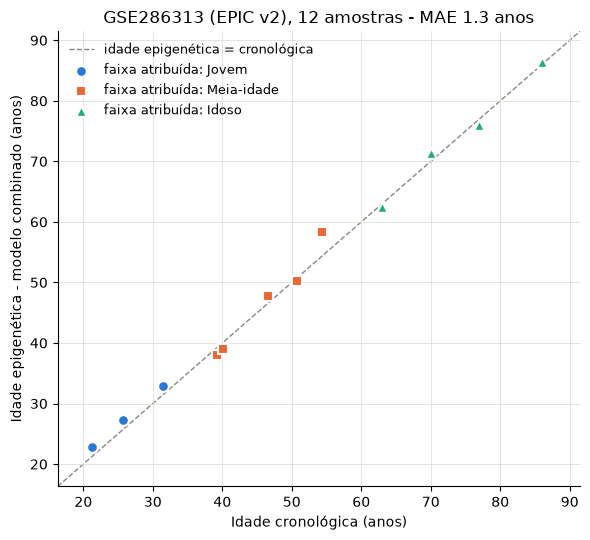

In [15]:
# Idade cronológica x epigenética; cor e forma = faixa atribuída pelo modelo geral
CORES = {"Jovem": "#2a78d6", "Meia-idade": "#eb6834", "Idoso": "#1baf7a"}
MARCAS = {"Jovem": "o", "Meia-idade": "s", "Idoso": "^"}

fig, ax = plt.subplots(figsize=(6, 5.5))
lim = (min(tabela["idade_cronologica"].min(), tabela["idade_epigenetica"].min()) - 5,
       max(tabela["idade_cronologica"].max(), tabela["idade_epigenetica"].max()) + 5)
ax.plot(lim, lim, color="#898781", lw=1, ls="--", label="idade epigenética = cronológica", zorder=1)
for faixa_nome in CORES:  # ordem fixa: Jovem, Meia-idade, Idoso
    grupo = tabela[tabela["faixa_atribuida"] == faixa_nome]
    ax.scatter(grupo["idade_cronologica"], grupo["idade_epigenetica"], s=60, zorder=2,
               color=CORES[faixa_nome], marker=MARCAS[faixa_nome], edgecolor="white", linewidth=1.5,
               label=f"faixa atribuída: {faixa_nome}")
ax.set(xlim=lim, ylim=lim, xlabel="Idade cronológica (anos)", ylabel="Idade epigenética - modelo combinado (anos)",
       title=f"GSE286313 (EPIC v2), {len(tabela)} amostras - MAE {mae_comb:.1f} anos")
ax.grid(color="#e1e0d9", lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 7. Testes

### 7.1 Amostra sintética

Criamos uma amostra artificial: os β médios da S2 com um pequeno ruído, só nos
CpGs do modelo e **sem** sufixo (formato 450K/EPIC v1). Esperado: idade plausível,
próxima da do "indivíduo médio" (~46 anos), cobertura de 100 % e nenhum
ausente. Também confere que a calculadora aceita IDs sem sufixo.

In [16]:
rng = np.random.default_rng(42)
cpgs_todos = MODELOS["Geral"]["cpgs"]
for m in MODELOS.values():
    cpgs_todos = cpgs_todos.union(m["cpgs"])

base = MEDIA_BETA.reindex(cpgs_todos)
sintetica = pd.DataFrame({
    "sintetica_media": base,
    "sintetica_ruido": (base + rng.normal(0, 0.01, len(base))).clip(0, 1),
})
rel_sint = calcular_idade_epigenetica(sintetica)
rel_sint.drop(columns="ausentes").round(2)

Normalização dos IDs:
  probes recebidos (linhas)            7,869
  com sufixo EPIC v2 removido              0
  CpGs com réplicas                        0
  probes envolvidos em réplicas            0
  CpGs únicos após normalização        7,869


,idade_epigenetica,idade_modelo_geral,faixa_atribuida,probes_recebidos,probes_requeridos_relogio,probes_usados_relogio,n_ausentes,cobertura_geral_%,cobertura_especifico_%,imputacao_usada,alerta
amostra,,,,,,,,,,,
sintetica_media,45.68,46.14,Meia-idade,7869,6141,6141,0,100.0,100.0,False,
sintetica_ruido,46.00,46.86,Meia-idade,7869,6141,6141,0,100.0,100.0,False,


### 7.2 Probes ausentes

Pegamos uma amostra real e removemos aleatoriamente 5 %, 20 % e 50 % dos CpGs
do modelo geral (apagando as linhas, com e sem sufixo). Esperado:

- a cobertura cai na proporção removida;
- os ausentes aparecem listados e a imputação é usada;
- abaixo de 90 % aparece o alerta;
- a idade se afasta da original e tende ao "indivíduo médio", porque os valores
  imputados são médias populacionais.

Como a remoção é sorteada entre os CpGs do modelo **geral**, a cobertura do
modelo específico cai um pouco menos (os modelos compartilham só parte dos CpGs).

In [17]:
AMOSTRA_TESTE = meta.index[0]
original = betas_geo[[AMOSTRA_TESTE]]
id_base = original.index.str.replace(SUFIXO_EPICV2, "", regex=True)

resultados = []
for frac in [0.0, 0.05, 0.20, 0.50]:
    remover = rng.choice(MODELOS["Geral"]["cpgs"], size=int(frac * len(MODELOS["Geral"]["cpgs"])), replace=False)
    teste = original[~id_base.isin(remover)].rename(columns={AMOSTRA_TESTE: f"removido_{frac:.0%}"})
    r = calcular_idade_epigenetica(teste, verbose=False).iloc[0]
    resultados.append({"removidos": f"{frac:.0%}", "idade_epigenetica": r["idade_epigenetica"],
                       "faixa": r["faixa_atribuida"], "cobertura_geral_%": r["cobertura_geral_%"],
                       "cobertura_especifico_%": r["cobertura_especifico_%"], "n_ausentes": r["n_ausentes"],
                       "imputacao_usada": r["imputacao_usada"], "alerta": r["alerta"]})

print(f"Amostra {AMOSTRA_TESTE}, idade cronológica {meta.loc[AMOSTRA_TESTE, 'idade']} anos")
pd.DataFrame(resultados).round(2)

Amostra GSM8723479, idade cronológica 21.3 anos


,removidos,idade_epigenetica,faixa,cobertura_geral_%,cobertura_especifico_%,n_ausentes,imputacao_usada,alerta
0,0%,22.89,Jovem,99.90,99.82,9,True,
1,5%,22.81,Jovem,94.90,96.61,253,True,
2,20%,23.53,Jovem,79.90,87.36,986,True,COBERTURA BAIXA
3,50%,35.05,Meia-idade,49.97,63.03,2444,True,COBERTURA BAIXA


Exemplo do relatório com probes ausentes (20 % removidos, recriado para mostrar
a lista):

In [18]:
remover = rng.choice(MODELOS["Geral"]["cpgs"], size=int(0.20 * len(MODELOS["Geral"]["cpgs"])), replace=False)
teste = original[~id_base.isin(remover)]
imprimir_relatorio(calcular_idade_epigenetica(teste, verbose=False), AMOSTRA_TESTE)

===== Relatório: GSM8723479 =====
Idade epigenética (modelo combinado): 25.7 anos
  idade preliminar (modelo geral):    23.7 anos -> faixa 'Jovem'
Probes recebidos:                     928,567
Probes usados pelo relógio:           5,346 de 6,330 necessários
Cobertura modelo geral:               79.94 %
Cobertura modelo 'Jovem':             87.23 %
Probes ausentes (984), imputados com o β médio da S2: cg00007076, cg00008629, cg00033551, cg00084577, cg00101715, cg00124004, cg00133476, cg00174992, cg00175344, cg00185867 ...
ALERTA: cobertura abaixo de 90%; idade menos confiável.


## 8. Interpretação e limitações

### Como ler o resultado

- **Idade epigenética** é uma estimativa da idade **cronológica** a partir da
  metilação. A diferença `idade epigenética - idade cronológica` é a *aceleração
  epigenética* (EAA). O artigo mostra que, nesse modelo, o ruído técnico entre
  réplicas fica em torno de 0,8 ano e a variação dentro do mesmo indivíduo em
  torno de 1 ano. Diferenças dessa ordem **não** devem ser interpretadas.
- A **cobertura** indica quanto do relógio foi realmente medido. Com cobertura
  alta (EPIC v2 de boa qualidade, > 99 %) a imputação é desprezível. Com cobertura
  baixa a idade é puxada para a média da população de treino e fica menos
  confiável, por isso o alerta abaixo de 90 % (o artigo não define limiar; este
  é uma escolha da calculadora).

### Limitações

- **Relógio de primeira geração:** treinado para prever idade cronológica, não
  risco de mortalidade nem "idade biológica" (como PhenoAge/GrimAge fazem). No
  artigo, o modelo detecta aumento da EAA com radioterapia e câncer de mama, mas
  menor que a variação normal da população, e nenhuma mudança com exercício.
- **Só sangue total:** os coeficientes não valem para outros tecidos (saliva,
  biópsias, células isoladas) sem recalibração.
- **Faixa etária dos dados de treino:** amostras fora da faixa bem representada
  (crianças pequenas, idades muito altas) tendem a ter mais erro, e o modelo
  combinado depende da faixa atribuída pelo modelo geral: uma amostra perto dos
  cortes (36 ou 59 anos) pode cair no modelo vizinho.
- **Pré-processamento:** o modelo foi treinado em β-values já normalizados de
  vários estudos. Normalizações diferentes (SeSAMe, minfi, Noob etc.) e efeito de
  lote podem deslocar a idade em alguns anos.
- **Imputação pela média:** é o método do artigo, mas enviesa as predições em
  direção à média quando há muitos ausentes.
- **Réplicas do EPIC v2:** agregamos pela média; outra estratégia (ex.: escolher a
  sonda de melhor qualidade) pode dar valores ligeiramente diferentes.
- **Validação limitada:** testamos em um único dataset externo (72 amostras no total, 12 no notebook), de adultos de 21 a 86 anos.